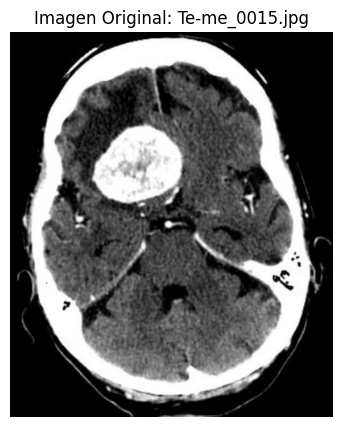

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import urllib.request

url = "https://raw.githubusercontent.com/dilp90/PDI/main/Imagenes/Te-me_0015.jpg"
urllib.request.urlretrieve(url, "Te-me_0015.jpg")

img_bgr = cv2.imread("Te-me_0015.jpg")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.title("Imagen Original: Te-me_0015.jpg")
plt.axis("off")
plt.show()

Parte 1

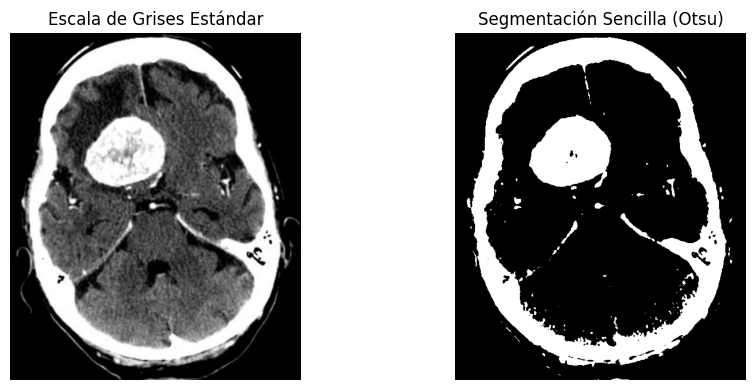

In [2]:
# Conversión estándar a escala de grises
gris_sencilla = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Umbralización automática de Otsu
_, seg_sencilla = cv2.threshold(gris_sencilla, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(gris_sencilla, cmap="gray")
plt.title("Escala de Grises Estándar")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(seg_sencilla, cmap="gray")
plt.title("Segmentación Sencilla (Otsu)")
plt.axis("off")
plt.tight_layout()
plt.show()

Parte 2


Coeficientes óptimos -> R: 0.3333, G: 0.3333, B: 0.3333


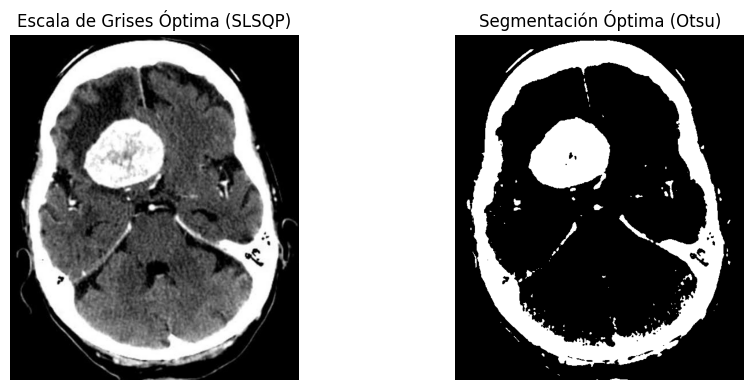

In [3]:
R = img_rgb[:, :, 0].astype(np.float64) / 255.0
G = img_rgb[:, :, 1].astype(np.float64) / 255.0
B = img_rgb[:, :, 2].astype(np.float64) / 255.0

def funcion_objetivo(pesos):
    w_r, w_g, w_b = pesos
    gris_pond = w_r * R + w_g * G + w_b * B
    return -np.var(gris_pond)

restriccion = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}
limites = [(0, 1), (0, 1), (0, 1)]
pesos_iniciales = [1/3, 1/3, 1/3]

resultado = minimize(
    funcion_objetivo,
    pesos_iniciales,
    method='SLSQP',
    bounds=limites,
    constraints=restriccion
)

w_opt = resultado.x
print(f"Coeficientes óptimos -> R: {w_opt[0]:.4f}, G: {w_opt[1]:.4f}, B: {w_opt[2]:.4f}")

gris_optima = (w_opt[0] * R + w_opt[1] * G + w_opt[2] * B) * 255.0
gris_optima = gris_optima.astype(np.uint8)
_, seg_optima = cv2.threshold(gris_optima, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(gris_optima, cmap="gray")
plt.title("Escala de Grises Óptima (SLSQP)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(seg_optima, cmap="gray")
plt.title("Segmentación Óptima (Otsu)")
plt.axis("off")
plt.tight_layout()
plt.show()

Parte 3

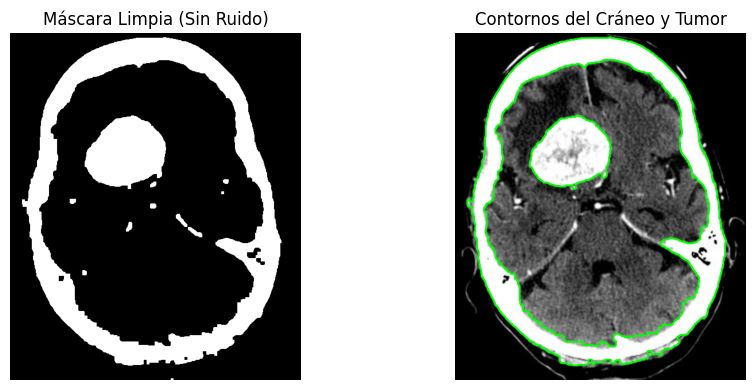

In [4]:
kernel = np.ones((5, 5), np.uint8)
sin_ruido = cv2.morphologyEx(seg_optima, cv2.MORPH_OPEN, kernel)
sin_ruido = cv2.morphologyEx(sin_ruido, cv2.MORPH_CLOSE, kernel)

contornos, _ = cv2.findContours(sin_ruido, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
img_contornos = img_rgb.copy()

contornos_principales = [c for c in contornos if cv2.contourArea(c) > 300]
cv2.drawContours(img_contornos, contornos_principales, -1, (0, 255, 0), 2)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(sin_ruido, cmap="gray")
plt.title("Máscara Limpia (Sin Ruido)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_contornos)
plt.title("Contornos del Cráneo y Tumor")
plt.axis("off")
plt.tight_layout()
plt.show()

Parte 4

Área estimada del tumor: 145899.50 píxeles cuadrados


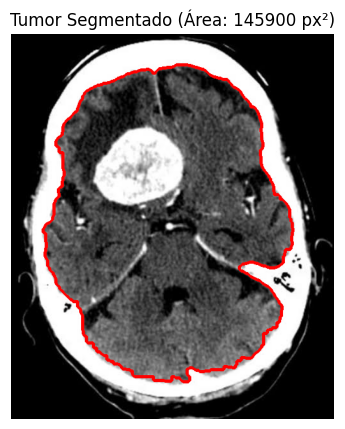

In [5]:

contornos_ordenados = sorted(contornos_principales, key=cv2.contourArea, reverse=True)

if len(contornos_ordenados) >= 2:
    contorno_tumor = contornos_ordenados[1]
    area_tumor = cv2.contourArea(contorno_tumor)

    img_tumor = img_rgb.copy()
    cv2.drawContours(img_tumor, [contorno_tumor], -1, (255, 0, 0), 3)

    print(f"Área estimada del tumor: {area_tumor:.2f} píxeles cuadrados")

    plt.figure(figsize=(5, 5))
    plt.imshow(img_tumor)
    plt.title(f"Tumor Segmentado (Área: {area_tumor:.0f} px²)")
    plt.axis("off")
    plt.show()
else:
    print("No se detectaron suficientes contornos principales. Ajusta el umbral de área o el kernel.")